In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Loading data

In [34]:
df = pd.read_csv('../Data/Cleaned_Data/datasaurus.csv')
print(df.columns)
print()
print(df["dataset"].unique())  
print()
print(df["dataset"].value_counts())

Index(['dataset', 'x', 'y'], dtype='str')

<StringArray>
[      'dino',       'away',    'h_lines',    'v_lines',    'x_shape',
       'star', 'high_lines',       'dots',     'circle',   'bullseye',
   'slant_up', 'slant_down', 'wide_lines']
Length: 13, dtype: str

dataset
dino          142
away          142
h_lines       142
v_lines       142
x_shape       142
star          142
high_lines    142
dots          142
circle        142
bullseye      142
slant_up      142
slant_down    142
wide_lines    142
Name: count, dtype: int64


## Cleaning data

In [35]:
print(df.isnull().sum())
df["x"] = df["x"].astype(np.float64)
df["y"] = df["y"].astype(np.float64)
df.info()

dataset    0
x          0
y          0
dtype: int64
<class 'pandas.DataFrame'>
RangeIndex: 1846 entries, 0 to 1845
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   dataset  1846 non-null   str    
 1   x        1846 non-null   float64
 2   y        1846 non-null   float64
dtypes: float64(2), str(1)
memory usage: 43.4 KB


## Computing mean, variance, Pearson correlation and the least-squares line

In [36]:
def compute_mean(arr: np.ndarray) -> float:
    return np.sum(arr) / len(arr)


def compute_sample_variance(arr: np.ndarray, mean_val: float) -> float:
    return np.sum((arr - mean_val) ** 2) / (len(arr) - 1)


def compute_correlation(
    x: np.ndarray, y: np.ndarray, mean_x: float, mean_y: float
) -> float:
    numerator = np.sum((x - mean_x) * (y - mean_y))
    denominator = np.sqrt(np.sum((x - mean_x) ** 2) * np.sum((y - mean_y) ** 2) )
    return numerator / denominator


def compute_linear_regression(
    x: np.ndarray, y: np.ndarray, mean_x: float, mean_y: float
) -> tuple[float, float]:
    beta_1 = np.sum((x - mean_x) * (y - mean_y)) / np.sum((x - mean_x) ** 2)
    beta_0 = mean_y - (beta_1 * mean_x)
    return beta_0, beta_1

## Stats of df_dino

In [52]:
dino = df[df['dataset'] == 'dino']
dino

,dataset,x,y
0,dino,55.3846,97.1795
1,dino,51.5385,96.0256
2,dino,46.1538,94.4872
3,dino,42.8205,91.4103
4,dino,40.7692,88.3333
...,...,...,...
137,dino,39.4872,25.3846
138,dino,91.2821,41.5385
139,dino,50.0000,95.7692
140,dino,47.9487,95.0000


In [53]:
dino_mean_x = compute_mean(dino['x'])
dino_mean_y = compute_mean(dino['y'])
print(dino_mean_x, " ", dino_mean_y)

54.26327323943662   47.832252816901416


In [54]:
dino_var_x = compute_sample_variance(dino['x'], dino_mean_x)
dino_var_y = compute_sample_variance(dino['y'], dino_mean_y)
print(dino_var_x, " ", dino_var_y)

281.069987591761   725.5159610042118


In [55]:
dino_pearson_xy = compute_correlation(dino["x"],dino['y'],dino_mean_x,dino_mean_y)
dino_pearson_xy

np.float64(-0.06447185270095167)

In [56]:
dino_slope = compute_linear_regression(dino["x"],dino['y'],dino_mean_x,dino_mean_y)
dino_slope

(np.float64(53.452978449229235), np.float64(-0.10358250243265602))

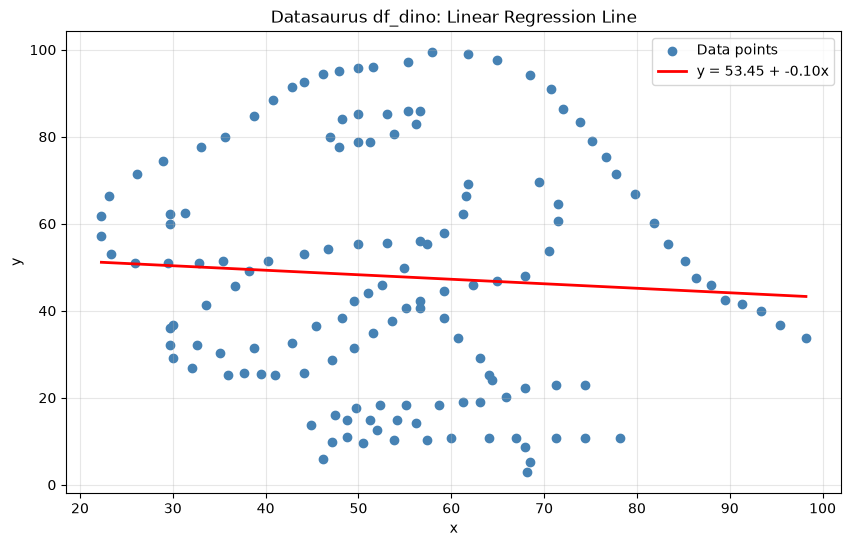

In [57]:
x_line = np.linspace(dino["x"].min(), dino["x"].max(), 100)
y_line = dino_slope[0] + dino_slope[1] * x_line

plt.figure(figsize=(10,6))
plt.scatter(dino["x"], dino["y"], color="steelblue", label="Data points")
plt.plot(x_line, y_line, color="red",
          linewidth=2, label=f"y = {dino_slope[0]:.2f} + {dino_slope[1]:.2f}x")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Datasaurus df_dino: Linear Regression Line")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## stats of df_away

In [58]:
away = df[df['dataset'] == 'away']
away

,dataset,x,y
142,away,32.331110,61.411101
143,away,53.421463,26.186880
144,away,63.920202,30.832194
145,away,70.289506,82.533649
146,away,34.118830,45.734551
...,...,...,...
279,away,59.851838,72.958391
280,away,48.960460,72.629526
281,away,46.844855,36.791714
282,away,39.963022,42.944915


In [59]:
away_mean_x = compute_mean(away['x'])
away_mean_y = compute_mean(away['y'])
print(away_mean_x, " ", away_mean_y)

54.266099784204926   47.83472062488412


In [60]:
away_var_x = compute_sample_variance(away['x'], away_mean_x)
away_var_y = compute_sample_variance(away['y'], away_mean_y)
print(away_var_x, " ", away_var_y)

281.2270289930791   725.7497754752688


In [61]:
away_pearson_xy = compute_correlation(away["x"],away['y'],away_mean_x,away_mean_y)
away_pearson_xy

np.float64(-0.0641283521547448)

In [62]:
away_slope = compute_linear_regression(away["x"],away['y'],away_mean_x,away_mean_y)
away_slope

(np.float64(53.4251300454603), np.float64(-0.10301844877017245))

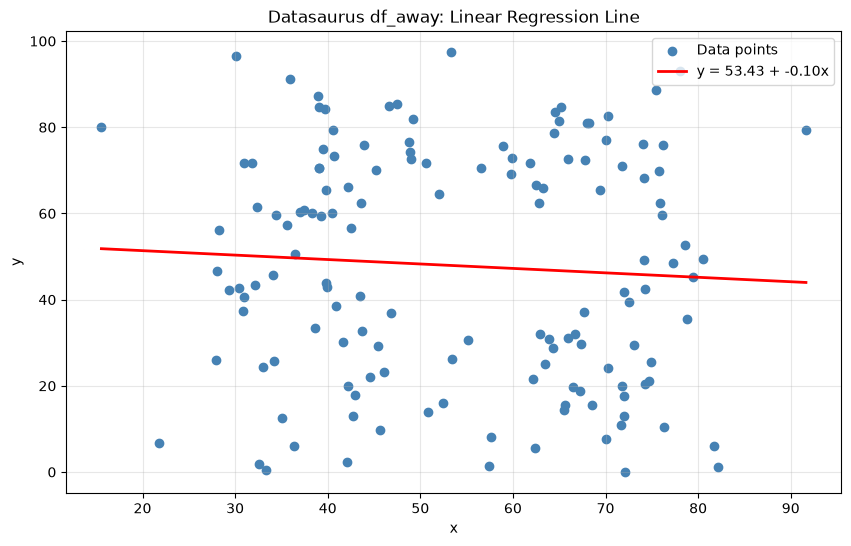

In [63]:
x_line = np.linspace(away["x"].min(), away["x"].max(), 100)
y_line = away_slope[0] + away_slope[1] * x_line

plt.figure(figsize=(10,6))
plt.scatter(away["x"], away["y"], color="steelblue", label="Data points")
plt.plot(x_line, y_line, color="red",
          linewidth=2, label=f"y = {away_slope[0]:.2f} + {away_slope[1]:.2f}x")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Datasaurus df_away: Linear Regression Line")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## stats of df_h_lines

In [70]:
h_lines = df[df['dataset'] == 'h_lines']
h_lines

,dataset,x,y
284,h_lines,53.366567,90.208030
285,h_lines,52.801979,90.088065
286,h_lines,47.054130,90.458936
287,h_lines,42.448434,89.507700
288,h_lines,42.704036,90.442629
...,...,...,...
421,h_lines,42.224120,30.498037
422,h_lines,87.698464,50.489937
423,h_lines,52.360331,89.704317
424,h_lines,51.406787,89.712139


In [ ]:
h_lines_mean_x = compute_mean(h_lines['x'])
h_lines_mean_y = compute_mean(h_lines['y'])
print(h_lines_mean_x, " ", h_lines_mean_y)

54.261441783514094   47.830251913635216


In [72]:
h_lines_var_x = compute_sample_variance(h_lines['x'], h_lines_mean_x)
h_lines_var_y = compute_sample_variance(h_lines['y'], h_lines_mean_y)
print(h_lines_var_x, " ", h_lines_var_y)

281.09533252964826   725.7569307510677


In [73]:
h_lines_pearson_xy = compute_correlation(h_lines["x"],h_lines['y'],h_lines_mean_x,h_lines_mean_y)
h_lines_pearson_xy

np.float64(-0.061714837956677766)

In [74]:
h_lines_slope = compute_linear_regression(h_lines["x"],h_lines['y'],h_lines_mean_x,h_lines_mean_y)
h_lines_slope

(np.float64(53.21108723737491), np.float64(-0.09916498985057419))

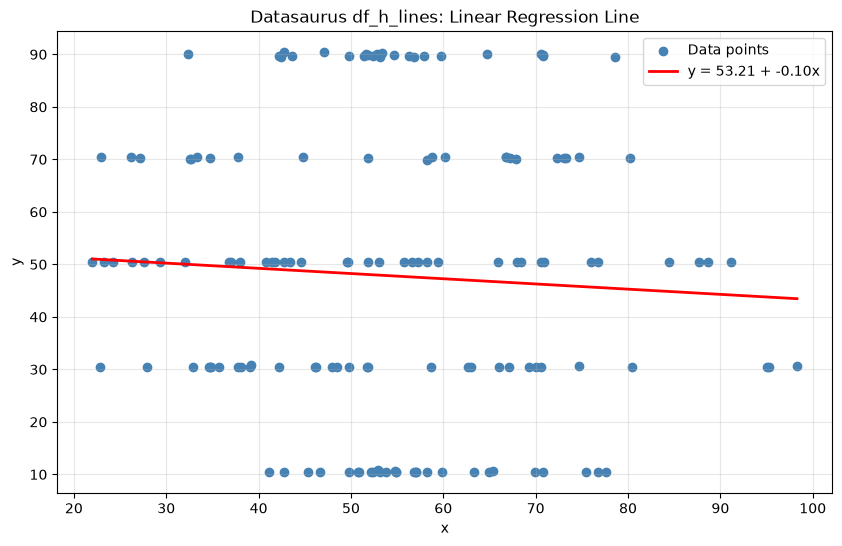

In [75]:
x_line = np.linspace(h_lines["x"].min(), h_lines["x"].max(), 100)
y_line = h_lines_slope[0] + h_lines_slope[1] * x_line

plt.figure(figsize=(10,6))
plt.scatter(h_lines["x"], h_lines["y"], color="steelblue", label="Data points")
plt.plot(x_line, y_line, color="red",
          linewidth=2, label=f"y = {h_lines_slope[0]:.2f} + {h_lines_slope[1]:.2f}x")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Datasaurus df_h_lines: Linear Regression Line")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Stats of df_v_lines

In [76]:
v_lines = df[df['dataset'] == 'v_lines']
v_lines

,dataset,x,y
426,v_lines,50.481508,93.222701
427,v_lines,50.282406,97.609984
428,v_lines,50.186703,99.694680
429,v_lines,50.326911,90.022053
430,v_lines,50.456207,89.987410
...,...,...,...
563,v_lines,30.487392,19.779470
564,v_lines,89.500180,31.978917
565,v_lines,50.410272,98.628369
566,v_lines,50.325924,94.994631


In [77]:
v_lines_mean_x = compute_mean(v_lines['x'])
v_lines_mean_y = compute_mean(v_lines['y'])
print(v_lines_mean_x, " ", v_lines_mean_y)

54.26992723102747   47.83698798816881


In [ ]:
v_lines_var_x = compute_sample_variance(v_lines['x'], v_lines_mean_x)
v_lines_var_y = compute_sample_variance(v_lines['y'], v_lines_mean_y)
print(v_lines_var_x, " ", v_lines_var_y)

In [78]:
v_lines_pearson_xy = compute_correlation(v_lines["x"],v_lines['y'],v_lines_mean_x,v_lines_mean_y)
v_lines_pearson_xy

np.float64(-0.06944556959817211)

In [79]:
v_lines_slope = compute_linear_regression(v_lines["x"],v_lines['y'],v_lines_mean_x,v_lines_mean_y)
v_lines_slope

(np.float64(53.890843393692265), np.float64(-0.11155082961051624))

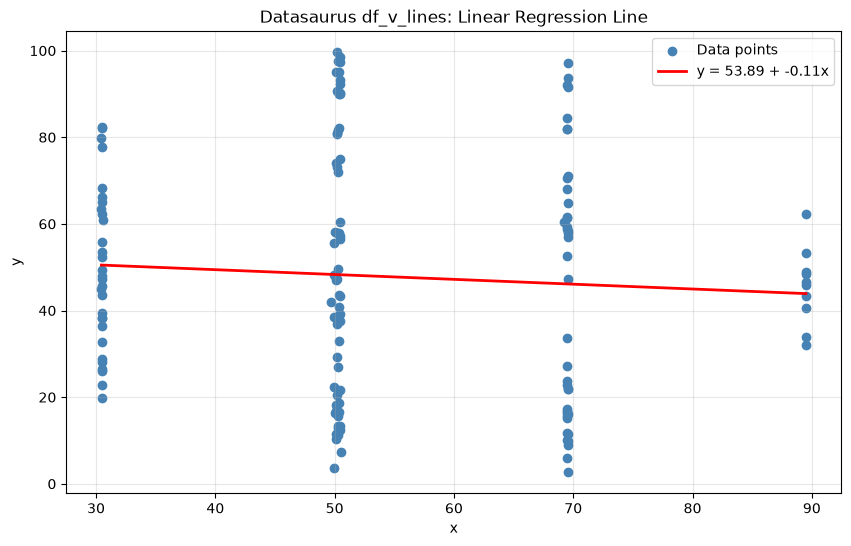

In [80]:
x_line = np.linspace(v_lines["x"].min(), v_lines["x"].max(), 100)
y_line = v_lines_slope[0] + v_lines_slope[1] * x_line

plt.figure(figsize=(10,6))
plt.scatter(v_lines["x"], v_lines["y"], color="steelblue", label="Data points")
plt.plot(x_line, y_line, color="red",
          linewidth=2, label=f"y = {v_lines_slope[0]:.2f} + {v_lines_slope[1]:.2f}x")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Datasaurus df_v_lines: Linear Regression Line")
plt.legend()
plt.grid(alpha=0.3)
plt.show()